In [1]:
import numpy as np

from particle_filter.models.transition import AdditiveTransitionModel
from particle_filter.models.observation import AdditiveObservationModel

from particle_filter.simulations import system_simulation

from particle_filter.plots.plot_results import plot_results
from particle_filter.plots.plot_comparisons import plot_comparisons
from particle_filter.plots.plot_EES import plot_ESS

from particle_filter.filtering_algorithms.particle_filter import BootstrapParticleFilter

from particle_filter.performance_metrics import RMSE, Interval_cover

En primer lugar, se describe el sistema unidimensional con el que se va a trabajar.

- Ecuación de transición:

$$
x_t = 0.95\cdot x_{t-1}  + w_t
$$

- Ecuación de observación:

$$
y_t = x_t + v_t
$$

### Caso 1: ruido de observacion con distribucion uniforme

In [2]:
# Funciones del sistema para PF
def f(x):

    return 0.95 * x

def h(x):

    return x

In [12]:
from particle_filter.models.noise import GaussianNoise

# Modelos de transicion
Q = np.array([[1.0]])

noise_transition = GaussianNoise(Q)
transition = AdditiveTransitionModel(f, noise_transition)

In [56]:
from particle_filter.models.noise import UniformNoise, ExponentialNoise, GammaNoise

# Modelo de observación
noise_observation = UniformNoise(np.array([0.5]), np.array([3.5]))
#noise_observation = ExponentialNoise(np.array([0.5]))
#noise_observation = GammaNoise(np.array([2.0]), np.array([2.0]))

observation = AdditiveObservationModel(f, noise_observation)

In [68]:
import pickle

T = 500
x0 = np.array([0.0])

n_simulations = 1

results_bpf = []
results_apf = []

for i in range(n_simulations):

    # Simulaciones
    x_true, y_obs = system_simulation(transition, observation, x0, T)

    # Ejecuciones filtrado
    bpf = BootstrapParticleFilter(1000, transition, observation)
    bpf.initialize(mean=np.array([0.0]), cov=np.eye(1))
    est_bpf = bpf.run_filter(y_obs, bpf.N/2)

    results_bpf.append({
        "simulation": i,
        "x_true": x_true,
        "y_obs": y_obs,
        "results": est_bpf
    })

    print(f"Simulacion {i+1} finalizada")
    
results = {
    "Bootstrap": results_bpf
}

with open("results_exp1_4_3.pkl", "wb") as file:
    pickle.dump(results, file)

Simulacion 1 finalizada


In [74]:
with open("results_exp1_4.pkl", "rb") as file:
    results = pickle.load(file)

results_bpf = results["Bootstrap"]

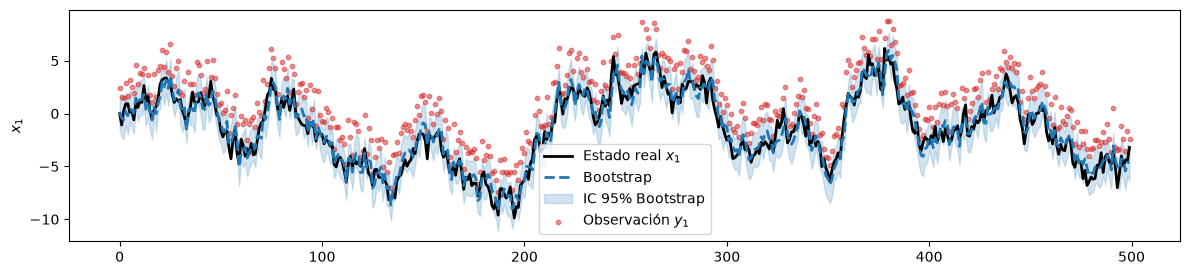

In [78]:
i=0

x_true = results_bpf[i]["x_true"]
y_obs = results_bpf[i]["y_obs"]

plot_results(x_true,y_obs,
             {"Bootstrap": results_bpf[i]["results"]["estimates"]},
              confidence_intervals={"Bootstrap": results_bpf[i]["results"]["intervals"]},
x_title="", plot_title=""
)


In [75]:
n_simulations = 10 

rmse_bpf = np.zeros(n_simulations)

loglikelihood_bpf = np.zeros(n_simulations)

IC_bpf = np.zeros(n_simulations)

for i in range(n_simulations):

    rmse_bpf[i] = RMSE(results_bpf[i]["x_true"], results_bpf[i]["results"]["estimates"])

    loglikelihood_bpf[i] = results_bpf[i]["results"]["log_likelihood"]

    IC_bpf[i] = Interval_cover(results_bpf[i]["x_true"], results_bpf[i]["results"]["intervals"])

print("RMSE")
print(f"Bootstrap Particle Filter: {np.mean(rmse_bpf)} +/- {np.std(rmse_bpf)}")

print("Log-verosimilitud estimada")
print(f"Bootstrap Particle Filter: {np.mean(loglikelihood_bpf)} +/- {np.std(loglikelihood_bpf)}")

print("Interval cover")
print(f"Bootstrap Particle Filter: {np.mean(IC_bpf)} +/- {np.std(IC_bpf)}")

RMSE
Bootstrap Particle Filter: 0.8029489242694225 +/- 0.04139528932310063
Log-verosimilitud estimada
Bootstrap Particle Filter: -943.1188812539582 +/- 12.478507786088283
Interval cover
Bootstrap Particle Filter: 94.46000000000001 +/- 1.2330450113438645


### Vehículo

In [5]:
from particle_filter.filtering_algorithms.particle_filter import BootstrapParticleFilterRegime
from particle_filter.models.transition import RegimeTransitionModel
from particle_filter.simulations import system_simulation_regime_model
from particle_filter.models.noise import UniformNoise, ExponentialNoise, GammaNoise, GaussianNoise

- Ecuación de transicion

$$
x_t = x_{t-1} + d(S_t) +w_t, \;\;\; w_t \sim \mathcal{N}(0,1.0)
$$

con $d(S_t)=+2,-2,0$ y matriz de transicion

$$
\begin{pmatrix}
0.8 &0.1 &0.1\\
0.1 &0.8 &0.1\\
0.4 &0.4 &0.2
\end{pmatrix}
$$

- Ecuacion de observacion

$$
y_t = x_t + v_t
$$

In [6]:
# Primera funcion de transicion
def f1(x):

    return np.array(x + 2.0)

Q1 = np.diag([1.0])

noise_transition_1 = GaussianNoise(Q1)
transition_1 = AdditiveTransitionModel(f1, noise_transition_1)

# Segunda funcion de transicion
def f2(x):

    return np.array(x - 2.0)

Q2 = np.diag([1.0])

noise_transition_2 = GaussianNoise(Q2)
transition_2 = AdditiveTransitionModel(f2, noise_transition_2)

# Tercera funcion de transicion
def f3(x):

    return np.array(x)

Q3 = np.diag([1.0])

noise_transition_3 = GaussianNoise(Q3)
transition_3 = AdditiveTransitionModel(f3, noise_transition_3)

# Funcion de transicion total
transition_models = [transition_1, transition_2, transition_3]
regimes_transition = [ [0.8, 0.1, 0.1], [0.1, 0.8, 0.1], [0.4, 0.4, 0.2] ]

transition_model = RegimeTransitionModel(transition_models, regimes_transition)

In [24]:
# Funcion de observacion
def h(x):

    return np.array(x)

# Ruido de observacion

#noise_observation = GaussianNoise(np.array([0.5]))
#noise_observation = GammaNoise(np.array([2.0]), np.array([2.0]))
#noise_observation = ExponentialNoise(np.array([0.5]))
noise_observation = UniformNoise(np.array([0.5]), np.array([3.0]))

observation_model = AdditiveObservationModel(h, noise_observation) 

In [ ]:
T = 500
N = 1000

regimen0 = np.random.choice(1)
x0 = np.array([1.0])

regimen_true, x_true, y_obs = system_simulation_regime_model(transition_model, observation_model, x0, regimen0, T)

results_bpf = []
results_apf = []

# Bootstrap PF
bpf = BootstrapParticleFilterRegime(
    N=N,
    transition_model=transition_model,
    observation_model=observation_model
)

#bpf.initialize(mean=np.array([0.0]), cov=np.diag([1.0]), initial_regime_probs=[1.0,0.0,0.0])
bpf.initialize(mean=np.array([0.0]), cov=np.diag([1.0]))

est_bpf = bpf.run_filter(y_obs, resample_threshold=bpf.N/2)

results_bpf.append({
    "simulation": 0,
    "x_true": x_true,
    "y_obs": y_obs,
    "regimen_true": regimen_true,
    "results": est_bpf        
    })

results = {
    "Bootstrap": results_bpf
}

with open("results_exp4_10.pkl", "wb") as file:

    pickle.dump(results, file)

In [8]:
import pickle

with open("results_exp4_12.pkl", "rb") as file:
    results = pickle.load(file)

results_bpf = results["Bootstrap"]

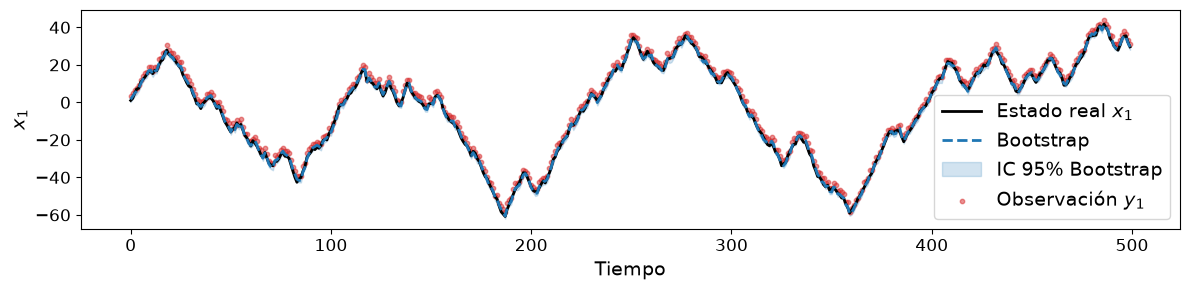

In [9]:
i=0

x_true = results_bpf[i]["x_true"]
y_obs = results_bpf[i]["y_obs"]
plot_results(x_true,y_obs,
             {"Bootstrap": results_bpf[i]["results"]["estimates"]},
              confidence_intervals={"Bootstrap": results_bpf[i]["results"]["intervals"]},
x_title="Tiempo", plot_title="Evolución del estado estimado"
)

In [45]:
n_simulations = 1

rmse_bpf = np.zeros(n_simulations)

loglikelihood_bpf = np.zeros(n_simulations)

IC_bpf = np.zeros(n_simulations)

for i in range(n_simulations):

    rmse_bpf[i] = RMSE(results_bpf[i]["x_true"], results_bpf[i]["results"]["estimates"])

    loglikelihood_bpf[i] = results_bpf[i]["results"]["log_likelihood"]

    IC_bpf[i] = Interval_cover(results_bpf[i]["x_true"], results_bpf[i]["results"]["intervals"])

print("RMSE")
print(f"Bootstrap Particle Filter: {np.mean(rmse_bpf)} +/- {np.std(rmse_bpf)}")

print("Log-verosimilitud estimada")
print(f"Bootstrap Particle Filter: {np.mean(loglikelihood_bpf)} +/- {np.std(loglikelihood_bpf)}")

print("Interval cover")
print(f"Bootstrap Particle Filter: {np.mean(IC_bpf)} +/- {np.std(IC_bpf)}")

RMSE
Bootstrap Particle Filter: 0.7536458429121737 +/- 0.0
Log-verosimilitud estimada
Bootstrap Particle Filter: -1058.6806713136398 +/- 0.0
Interval cover
Bootstrap Particle Filter: 95.19999999999999 +/- 0.0
